# Task 3: Work with YourTTS

## Introduction

### Context

### Aim

This project aims to experiemnt with a popular Text-to-speech (TTS) model to see how it handles synthesising speech in an established language(English) compared to a languages that is not conventionally supported by the model (Lithuanian).

## Methodology

### Data Description

Three sources of speech are used:
- **English reference recording**: own recording of the sentence *"This is a test of the speech synthesis system."*
- **Lithuanian reference recording**: own recording of the sentence *"Tai yra šnekos sintezės sistemos testas."*
- **Lithuanian Emotional Speech Corpus (EMO):** only one WAV archive (`emo-wavs.zip.009`) is downloaded, not the full corpus.

The corpus metadata (`metadata_of_EMO_dataset.csv`) describes the whole corpus:
- 349,696 rows, pipe-separated (`|`), no header row, UTF-8 encoded;
- three columns: relative WAV path, two-digit speaker ID and transcription;
- the WAV path follows `wavs/<emotion>/<group>/<speaker ID><session>-<group><emotion>/<...>-<recording number>.wav`.

Emotion labels:
- D – Joy: 69,642 recordings;
- L – Sadness: 71,401 recordings;
- N – Surprise: 68,103 recordings;
- P – Anger: 72,463 recordings;
- Z – Neutral: 68,087 recordings;

There are 89 speaker IDs, each belonging to one of five groups: F2, F3, F4, M3 and M4 (likely gender and age group, to be confirmed with the corpus documentation). Groups F3 and M3 hold most of the speakers. A single speaker has roughly 250 recordings per emotion, and the sentences differ between emotions.

### Used Tools

The YourTTS model is selected for its established speech synthesis capabilities in the English language. It serves as a comparison when comparing speech synthesis of untrained language to one with more training material.

Python 3.10.11 is used for this task.

In accordance with the principle of proportionality, the architecture and depth of the YourTTS model fine-tuning will be adapted to the available computational resources. The current model is trained on a laptop computer equipped with 32 GB of RAM and a GPU with 8 GB of dedicated VRAM. These resources will be considered when determining the number of parameters and epochs and the amount of training data that will be used to ensure that the training process remains computationally feasible and timely.

### Applied Methods

The following procedures will be used in this project to experiment how different languages are synthesised:
- **Zero-shot synthesis**;
- **Adding additional training material**;
- **Model Fine-Tuning**.

Main evaluation criteria are visual inspection and quantitative metric comparison.

## 1. Preparation for Work

### Dataset Loading and Inspection

Necessary libraries are loaded into the environment.

In [54]:
# File handling libraries
import json
from pathlib import Path
import shutil

# Data analysis related libraries
import math
import numpy as np
import pandas as pd

# Machine learning libraries
import torch
from sklearn.model_selection import train_test_split, KFold

# Speech synthesis libraries
from TTS.api import TTS
from TTS.tts.configs.shared_configs import BaseDatasetConfig
from TTS.tts.datasets import load_tts_samples

# Visualisation libraries
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# TTS switches matplotlib outputs to the non-interactive objects
%matplotlib inline

# Custom functions
import speechsynth

Uniform colour map is declared so all outputs possess similar colour schemes.

Additional considerations for people possessing poor visibility were taken into account.

In [55]:
static_cmap = ["salmon", "skyblue"]
cmap = LinearSegmentedColormap.from_list("custom", ["#c6fcff", "#ffffff", "#FA8072"])

### File Locations

All file locations used in the project are defined in one place.

In [56]:
project_path = Path(r"C:\Users\Lenovo\Desktop\vu_masters\1_semester\natural_language_and_speech_processing\6_assignments\task_3")

recordings_path = project_path / "recordings"
emo_path = project_path / "emo_corpus"
emo_wavs_path = emo_path / "used_dataset" / "wavs"
training_wavs_path = emo_path / "used_dataset" / "training_wavs"
val_wavs_path = emo_path / "used_dataset" / "val_wavs"
metadata_train_path = emo_path / "used_dataset" / "metadata_train.csv"
metadata_val_path = emo_path / "used_dataset" / "metadata_val.csv"
outputs_path = project_path / "outputs"
dataset_path = project_path / "dataset"
finetune_path = project_path / "finetune"
metadata_path = project_path / "emo_corpus" / "metadata_of_EMO_dataset.csv"

### Loading the Pretrained YourTTS Model

The pretrained YourTTS model is loaded onto the GPU if available, otherwise the CPU. A fixed seed is also defined here and used for every random step in the notebook: speech synthesis, the choice of speaker and emotion, and the training/validation split. The model's output sampling frequency (`model_sr`) is stored as well: the natural recordings are loaded at this rate, so natural and synthesised speech are compared over the same frequency band.

In [57]:
device = "cuda" if torch.cuda.is_available() else "cpu"
gen_seed = 20260924

tts = TTS(model_name="tts_models/multilingual/multi-dataset/your_tts").to(device)
model_sr = tts.synthesizer.output_sample_rate

print(f"YourTTS loaded on: {device}")
print(f"Multi-speaker: {tts.is_multi_speaker} | Multilingual: {tts.is_multi_lingual}")
print(f"Built-in speakers: {len(tts.speakers)}")
print(f"Output sampling frequency: {model_sr} Hz")

 > tts_models/multilingual/multi-dataset/your_tts is already downloaded.
 > Using model: vits
 > Setting up Audio Processor...
 | > sample_rate:16000
 | > resample:False
 | > num_mels:80
 | > log_func:np.log10
 | > min_level_db:0
 | > frame_shift_ms:None
 | > frame_length_ms:None
 | > ref_level_db:None
 | > fft_size:1024
 | > power:None
 | > preemphasis:0.0
 | > griffin_lim_iters:None
 | > signal_norm:None
 | > symmetric_norm:None
 | > mel_fmin:0
 | > mel_fmax:None
 | > pitch_fmin:None
 | > pitch_fmax:None
 | > spec_gain:20.0
 | > stft_pad_mode:reflect
 | > max_norm:1.0
 | > clip_norm:True
 | > do_trim_silence:False
 | > trim_db:60
 | > do_sound_norm:False
 | > do_amp_to_db_linear:True
 | > do_amp_to_db_mel:True
 | > do_rms_norm:False
 | > db_level:None
 | > stats_path:None
 | > base:10
 | > hop_length:256
 | > win_length:1024


C:\Users\Lenovo\AppData\Roaming\Python\Python310\site-packages\TTS\utils\io.py:54: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(f, map_location=map_locati

 > Model fully restored. 
 > Setting up Audio Processor...
 | > sample_rate:16000
 | > resample:False
 | > num_mels:64
 | > log_func:np.log10
 | > min_level_db:-100
 | > frame_shift_ms:None
 | > frame_length_ms:None
 | > ref_level_db:20
 | > fft_size:512
 | > power:1.5
 | > preemphasis:0.97
 | > griffin_lim_iters:60
 | > signal_norm:False
 | > symmetric_norm:False
 | > mel_fmin:0
 | > mel_fmax:8000.0
 | > pitch_fmin:1.0
 | > pitch_fmax:640.0
 | > spec_gain:20.0
 | > stft_pad_mode:reflect
 | > max_norm:4.0
 | > clip_norm:False
 | > do_trim_silence:False
 | > trim_db:60
 | > do_sound_norm:False
 | > do_amp_to_db_linear:True
 | > do_amp_to_db_mel:True
 | > do_rms_norm:True
 | > db_level:-27.0
 | > stats_path:None
 | > base:10
 | > hop_length:160
 | > win_length:400
 > External Speaker Encoder Loaded !!
 > initialization of language-embedding layers.
 > Model fully restored. 
 > Setting up Audio Processor...
 | > sample_rate:16000
 | > resample:False
 | > num_mels:64
 | > log_func:np.log10

The model files are downloaded on the first run and cached locally, so later runs load them from disk.

The model is both multi-speaker and multilingual, so every synthesis call needs a speaker and a language. Instead of one of the built-in speakers, the speaker is given as a reference recording (`speaker_wav`), which is what makes the synthesis zero-shot: the model imitates a voice it has never been trained on.

### Supported Languages

Languages supported by the pretrained model are listed and checked for Lithuanian.

In [58]:
print(f"Supported languages: {tts.languages}")

lithuanian_supported = any(lang.split("-")[0] == "lt" for lang in tts.languages)
print(f"Lithuanian supported: {lithuanian_supported}")

Supported languages: ['en', 'fr-fr', 'pt-br']
Lithuanian supported: False


Lithuanian is not among the supported languages. In segment 3 the Lithuanian sentence is therefore synthesised with the English language setting, so the model reads Lithuanian text with English pronunciation rules.

## 2. Zero-Shot Speech Synthesis (English)

### Reference Recording

Own recording of the sentence *"This is a test of the speech synthesis system."*, saved as `reference_en.wav`. It serves both as the natural speech reference and as the target speaker's voice. It is loaded as mono at the model's sampling frequency (16 kHz), so it matches the synthesised speech in every comparison below.

In [59]:
sentence_en = "This is a test of the speech synthesis system."
reference_en_path = recordings_path / "reference_en.wav"

reference_en, reference_en_sr = speechsynth.load_recording(reference_en_path, sr=model_sr)
speechsynth.play_audio(reference_en, reference_en_sr, label=f"Natural speech: {sentence_en}")

Natural speech: This is a test of the speech synthesis system.


#### Recording Details

Duration, sampling frequency and audio format of the reference recording file, before it is downsampled to the model's sampling frequency.

In [60]:
pd.Series(speechsynth.recording_details(reference_en_path))

File                        reference_en.wav
Duration (s)                           4.693
Sampling frequency (Hz)                48000
Bit depth                                 16
Channels                                   2
Format                                   WAV
Encoding                   Signed 16 bit PCM
dtype: object

### Synthesising the Sentence

The same sentence is synthesised with the pretrained model, using `reference_en.wav` as the speaker reference and the English language setting, and saved as `outputs/output_en.wav`.

In [61]:
output_en_path = outputs_path / "output_en.wav"
outputs_path.mkdir(exist_ok=True)

torch.manual_seed(gen_seed)
tts.tts_to_file(
    text=sentence_en,
    speaker_wav=str(reference_en_path),
    language="en",
    file_path=str(output_en_path),
)

 > Text splitted to sentences.
['This is a test of the speech synthesis system.']


 > Processing time: 0.9554519653320312
 > Real-time factor: 0.2689141472930006


'C:\\Users\\Lenovo\\Desktop\\vu_masters\\1_semester\\natural_language_and_speech_processing\\6_assignments\\task_3\\outputs\\output_en.wav'

### Quality of the Synthesised Speech

Natural and synthesised recordings are played side by side. The synthesised speech is judged by ear on intelligibility, naturalness of rhythm and intonation, similarity to the reference speaker's voice, and audible artefacts.

In [62]:
synth_en, synth_en_sr = speechsynth.load_recording(output_en_path, sr=model_sr)

signals_en = {
    "Natural": (reference_en, reference_en_sr),
    "Synthesised": (synth_en, synth_en_sr),
}
speechsynth.play_side_by_side(signals_en)

### Acoustic Comparison

#### Waveforms

Both waveforms share the same time axis, so differences in duration and pauses are visible directly. Each waveform is scaled to its own peak, because the natural recording is far quieter than the synthesised one, which the TTS library saves normalised to full scale. The loudness difference is given by the RMS level in the table at the end of this section.

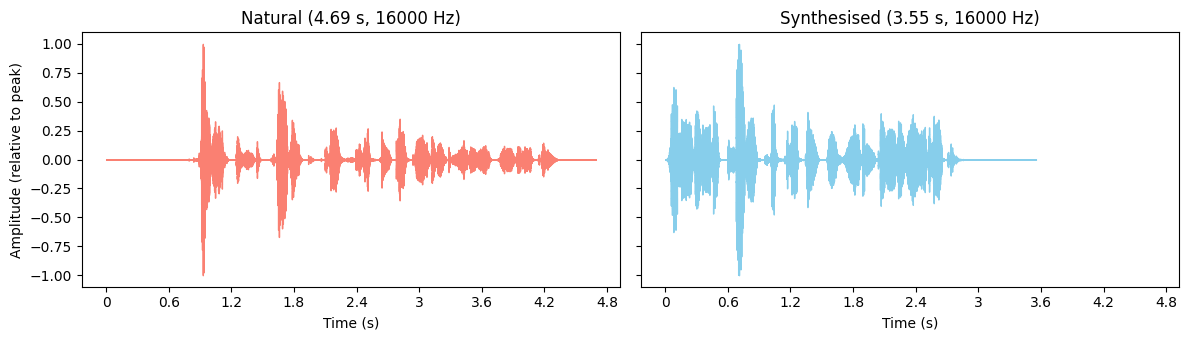

In [63]:
speechsynth.plot_waveforms(signals_en, colours=static_cmap)

#### Magnitude Spectrum

The magnitude spectrum shows how the energy of the whole recording is spread over frequency, without the time dimension: the voice's harmonics and formant regions at low frequencies and fricative noise at high frequencies. It is estimated with Welch's method (40 ms frames averaged over the recording) and shown in dB relative to each signal's own peak, so the two signals are compared by spectral shape rather than loudness. Both signals are at 16 kHz, so both spectra cover the same band, up to the Nyquist frequency of 8 kHz. The sharp drop of the natural spectrum just below 8 kHz comes from the anti-aliasing filter applied when the recording is downsampled to 16 kHz, not from the speech itself.

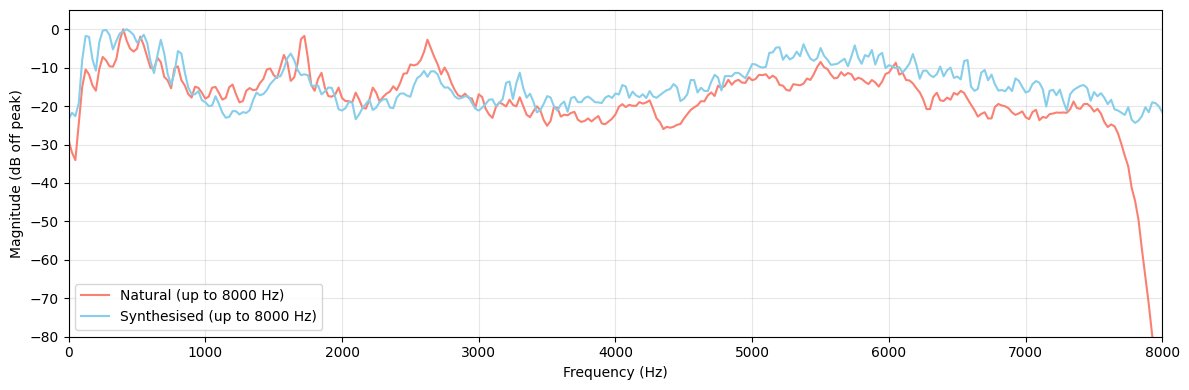

In [64]:
speechsynth.plot_magnitude_spectra(signals_en, colours=static_cmap)

#### Spectrograms

Spectrograms show how the spectrum changes over time: formant movements, fricative noise (e.g. /s/) and the silent gaps between words. Both use 25 ms frames with a 10 ms hop, share time and frequency axes, and are shown in dB relative to their own peak, so a difference in loudness does not hide a difference in spectral content. Both signals are at 16 kHz, so both cover the same band, up to the Nyquist frequency of 8 kHz.

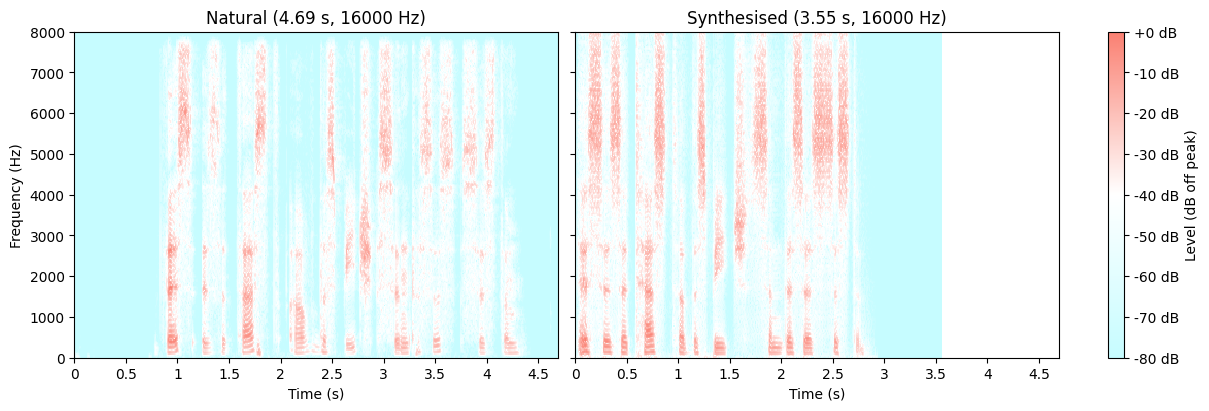

In [65]:
speechsynth.plot_spectrograms(signals_en, cmap=cmap)

#### F0 Contours on Normalised Time

The two signals differ in duration and pitch level, which makes their intonation patterns hard to compare on the plot above. Here both contours are stretched to the same length (0 = start of speech, 1 = end of speech) and shown in semitones relative to their own median F0.

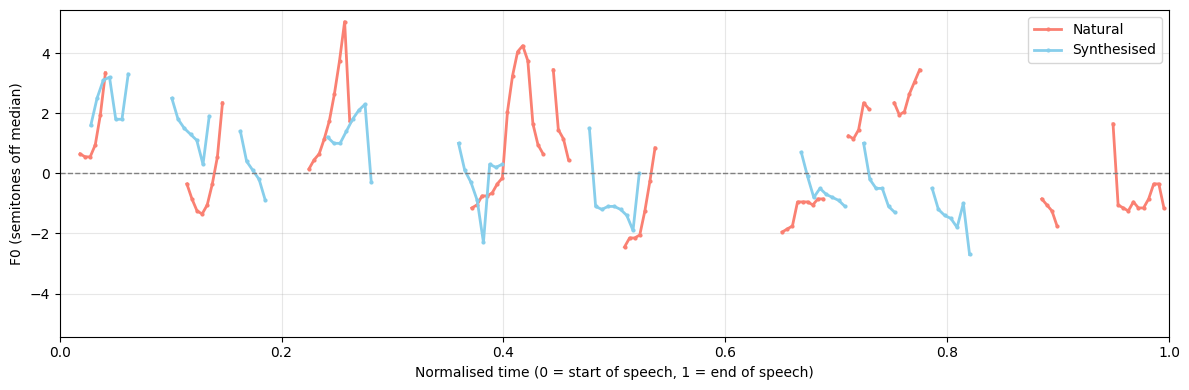

In [66]:
f0_en = speechsynth.f0_contours(signals_en)
speechsynth.plot_f0_normalised(signals_en, f0_en, colours=static_cmap)

### Observed Differences

Comparison of the natural and synthesised signals in terms of duration, spectral characteristics and F0 patterns.

The table summarises the measures behind the plots:
- **Duration and Speech duration:** full file length, and length after trimming leading and trailing silence (quieter than 30 dB below the peak).
- **RMS level:** average loudness of the speech part, in dB relative to full scale.
- **Spectral centroid:** the spectrum's centre of mass. A higher value means a brighter sound.
- **F0 mean, standard deviation, minimum and maximum:** pitch level and how much it varies.
- **F0 range:** distance between the lowest and highest pitch in semitones; flatter, more monotonous intonation gives a smaller range.

Both signals are at the same sampling frequency, so the spectral centroid covers the same frequency band and is comparable.

In [67]:
comparison_en = speechsynth.signal_comparison(signals_en, f0_en)
comparison_en.round(3)

,Natural,Synthesised
Duration (s),4.693,3.553
Speech duration (s),3.488,2.848
Sampling frequency (Hz),16000.000,16000.000
RMS level (dBFS),-40.311,-21.510
Spectral centroid (Hz),3159.726,3399.700
F0 mean (Hz),131.120,128.776
F0 std (Hz),13.912,10.704
F0 min (Hz),110.443,108.545
F0 max (Hz),170.326,153.506
F0 range (semitones),7.500,6.000


## 3. Zero-Shot Speech Synthesis (Lithuanian)

### Reference Recording

Own recording of the sentence *"Tai yra šnekos sintezės sistemos testas."*, saved as `reference_lt.wav`. It is loaded as mono at the model's sampling frequency (16 kHz), so it matches the synthesised speech in every comparison below.

In [68]:
sentence_lt = "Tai yra šnekos sintezės sistemos testas."
reference_lt_path = recordings_path / "reference_lt.wav"

reference_lt, reference_lt_sr = speechsynth.load_recording(reference_lt_path, sr=model_sr)
speechsynth.play_audio(reference_lt, reference_lt_sr, label=f"Natural speech: {sentence_lt}")

Natural speech: Tai yra šnekos sintezės sistemos testas.


#### Recording Details

Duration, sampling frequency and audio format of the reference recording.

In [69]:
pd.Series(speechsynth.recording_details(reference_lt_path))

File                        reference_lt.wav
Duration (s)                           5.163
Sampling frequency (Hz)                48000
Bit depth                                 16
Channels                                   2
Format                                   WAV
Encoding                   Signed 16 bit PCM
dtype: object

### Synthesising the Sentence

Since Lithuanian is not supported by the pretrained model, the sentence is synthesised using the English language setting and saved as `outputs/output_lt.wav`. The seed is fixed right before the call, as for English.

If a Lithuanian letter (e.g. š or ė) is missing from the model's character set, TTS drops it and prints a `Character ... not found in the vocabulary` warning in the cell output. Dropped letters are never pronounced, so any such warnings are worth noting when judging the quality.

In [70]:
output_lt_path = outputs_path / "output_lt.wav"
outputs_path.mkdir(exist_ok=True)

torch.manual_seed(gen_seed)
tts.tts_to_file(
    text=sentence_lt,
    speaker_wav=str(reference_lt_path),
    language="en",
    file_path=str(output_lt_path),
)

 > Text splitted to sentences.
['Tai yra šnekos sintezės sistemos testas.']
tai yra šnekos sintezės sistemos testas.
 [!] Character 'š' not found in the vocabulary. Discarding it.
tai yra šnekos sintezės sistemos testas.
 [!] Character 'ė' not found in the vocabulary. Discarding it.
 > Processing time: 1.2840912342071533
 > Real-time factor: 0.3301854549259844


'C:\\Users\\Lenovo\\Desktop\\vu_masters\\1_semester\\natural_language_and_speech_processing\\6_assignments\\task_3\\outputs\\output_lt.wav'

### Quality of the Synthesised Speech

Natural and synthesised recordings are played side by side. The synthesised speech is judged by ear on intelligibility, naturalness of rhythm and intonation, similarity to the reference speaker's voice, and audible artefacts.

In [71]:
synth_lt, synth_lt_sr = speechsynth.load_recording(output_lt_path, sr=model_sr)

signals_lt = {
    "Natural": (reference_lt, reference_lt_sr),
    "Synthesised": (synth_lt, synth_lt_sr),
}
speechsynth.play_side_by_side(signals_lt)

### Acoustic Comparison

The natural reference recording and the synthesised output are compared at the model's sampling frequency (16 kHz), as in section 2.

#### Waveforms

Both waveforms share the same time axis and are scaled to their own peaks, as in section 2.

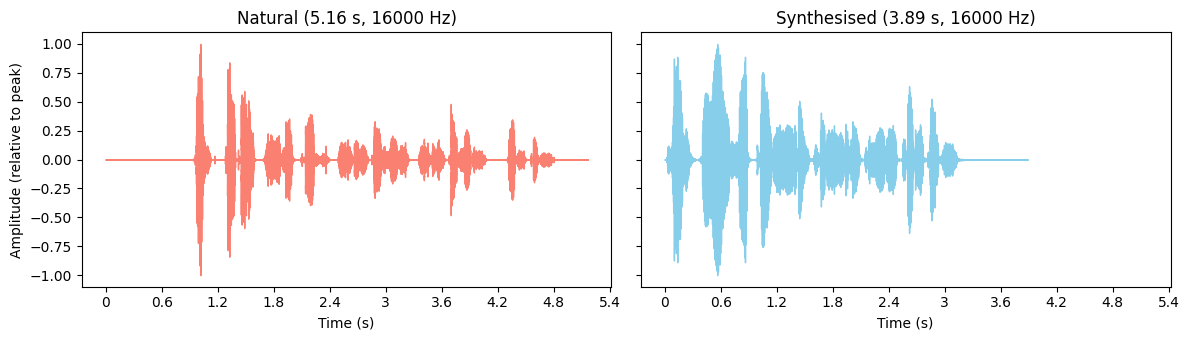

In [72]:
speechsynth.plot_waveforms(signals_lt, colours=static_cmap)

#### Magnitude Spectrum

Magnitude spectra with the same settings as in section 2 (Welch's method, 40 ms frames, dB relative to each signal's own peak).

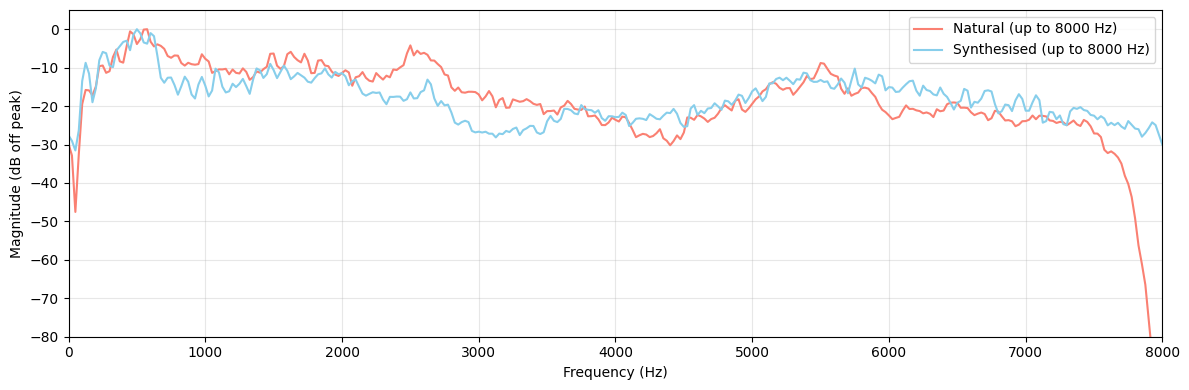

In [73]:
speechsynth.plot_magnitude_spectra(signals_lt, colours=static_cmap)

#### Spectrograms

Spectrograms with the same settings as in section 2 (25 ms frames, 10 ms hop, shared axes).

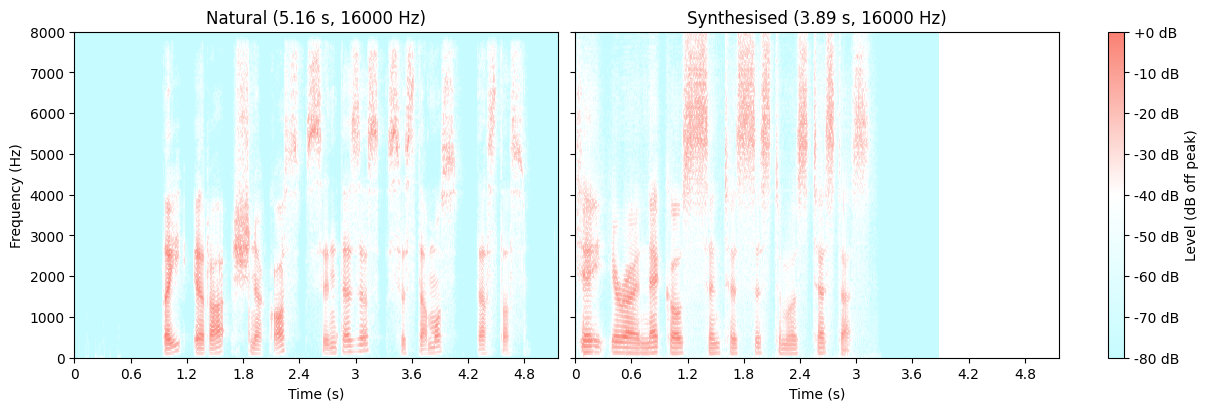

In [74]:
speechsynth.plot_spectrograms(signals_lt, cmap=cmap)

#### F0 Contours on Normalised Time

Both contours stretched to the same length and shown in semitones relative to their own median F0, as in section 2, so only the shape of the intonation is compared.

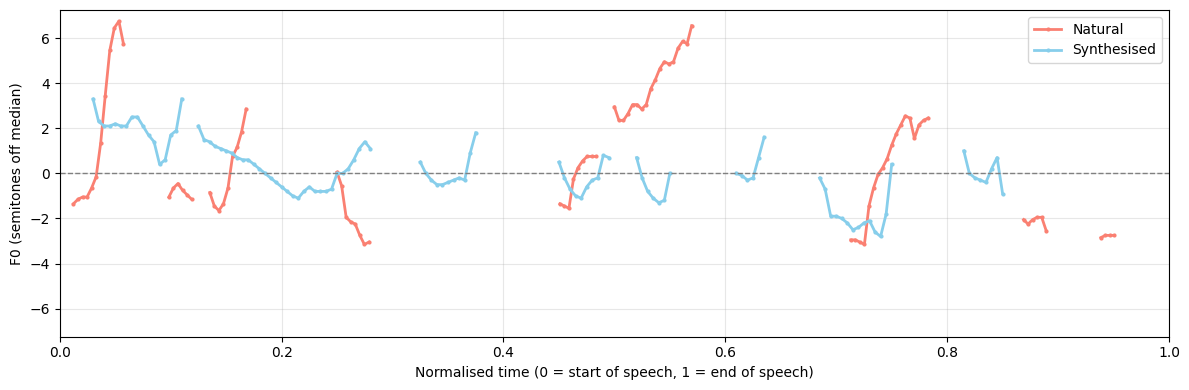

In [75]:
f0_lt = speechsynth.f0_contours(signals_lt)
speechsynth.plot_f0_normalised(signals_lt, f0_lt, colours=static_cmap)

### Observed Differences

Comparison of the natural and synthesised signals in terms of duration, spectral characteristics and F0 patterns, and how they differ from the English case.

The same measures as in section 2 are computed for the Lithuanian sentence.

In [76]:
comparison_lt = speechsynth.signal_comparison(signals_lt, f0_lt)
comparison_lt.round(3)

,Natural,Synthesised
Duration (s),5.163,3.889
Speech duration (s),3.904,3.200
Sampling frequency (Hz),16000.000,16000.000
RMS level (dBFS),-42.598,-20.037
Spectral centroid (Hz),3010.783,3182.539
F0 mean (Hz),126.893,124.521
F0 std (Hz),20.932,9.451
F0 min (Hz),100.693,104.848
F0 max (Hz),178.381,149.136
F0 range (semitones),9.900,6.100


Both languages side by side, to show how the gap between natural and synthesised speech changes when the language is not supported.

In [77]:
pd.concat({"English": comparison_en, "Lithuanian": comparison_lt}, axis=1).round(3)

English             Lithuanian            
                           Natural Synthesised    Natural Synthesised
Duration (s)                 4.693       3.553      5.163       3.889
Speech duration (s)          3.488       2.848      3.904       3.200
Sampling frequency (Hz)  16000.000   16000.000  16000.000   16000.000
RMS level (dBFS)           -40.311     -21.510    -42.598     -20.037
Spectral centroid (Hz)    3159.726    3399.700   3010.783    3182.539
F0 mean (Hz)               131.120     128.776    126.893     124.521
F0 std (Hz)                 13.912      10.704     20.932       9.451
F0 min (Hz)                110.443     108.545    100.693     104.848
F0 max (Hz)                170.326     153.506    178.381     149.136
F0 range (semitones)         7.500       6.000      9.900       6.100

## 4. Lithuanian Dataset Preparation

### EMO Corpus Metadata

#### Loading and Inspecting the Metadata

The metadata file is loaded and the WAV path is split into emotion, speaker group, speaker ID and session.

In [78]:
emotions = {"D": "Joy", "L": "Sadness", "N": "Surprise", "P": "Anger", "Z": "Neutral"}

metadata = pd.read_csv(metadata_path, sep="|", header=None, names=["path", "speaker_id", "text"],
                       dtype=str, encoding="utf-8")

path_parts = metadata["path"].str.split("/", expand=True)
metadata["emotion"] = path_parts[1]
metadata["group"] = path_parts[2]
metadata["session"] = path_parts[3].str[2:4]
metadata["file"] = path_parts[4]

print(f"Recordings: {len(metadata)} | Speakers: {metadata['speaker_id'].nunique()} | "
      f"Groups: {sorted(metadata['group'].unique())} | Emotions: {sorted(metadata['emotion'].unique())}")
metadata.head()

Recordings: 349696 | Speakers: 89 | Groups: ['F2', 'F3', 'F4', 'M3', 'M4'] | Emotions: ['D', 'L', 'N', 'P', 'Z']


,path,speaker_id,text,emotion,group,session,file
0,wavs/D/F2/0701-F2D/0701-F2D-0001.wav,07,džiugios naujienos iš čekijos,D,F2,01,0701-F2D-0001.wav
1,wavs/D/F2/0701-F2D/0701-F2D-0002.wav,07,sėkmė lydėjo mūsų mokyklos mokinį vilių,D,F2,01,0701-F2D-0002.wav
2,wavs/D/F2/0701-F2D/0701-F2D-0003.wav,07,čekijos sostinėje prahoje vykusiame tarptautin...,D,F2,01,0701-F2D-0003.wav
3,wavs/D/F2/0701-F2D/0701-F2D-0004.wav,07,festivalyje laimėta pirmoji vieta,D,F2,01,0701-F2D-0004.wav
4,wavs/D/F2/0701-F2D/0701-F2D-0005.wav,07,didžiuojamės ir džiaugiamės įspūdingu pasiekim...,D,F2,01,0701-F2D-0005.wav


#### Recordings per Emotion and Speaker

Number of speakers and recordings per emotion in each speaker group:

In [79]:
per_group = pd.crosstab(metadata["group"], metadata["emotion"].map(emotions), margins=True, margins_name="Total")
speakers_per_group = metadata.groupby("group")["speaker_id"].nunique()
speakers_per_group["Total"] = metadata["speaker_id"].nunique()
per_group.insert(0, "Speakers", speakers_per_group)
per_group

emotion,Speakers,Anger,Joy,Neutral,Sadness,Surprise,Total
group,,,,,,,
F2,2,538,489,485,544,465,2521
F3,42,33829,33238,32729,33674,32094,165564
F4,4,1769,1704,1415,1614,1520,8022
M3,35,32901,30776,30285,32018,30694,156674
M4,6,3426,3435,3173,3551,3330,16915
Total,89,72463,69642,68087,71401,68103,349696


Distribution of the number of recordings a single speaker has per emotion:

In [80]:
pd.crosstab(metadata["speaker_id"], metadata["emotion"].map(emotions)).describe().round(0)

emotion,Anger,Joy,Neutral,Sadness,Surprise
count,89.0,89.0,89.0,89.0,89.0
mean,814.0,782.0,765.0,802.0,765.0
std,746.0,710.0,710.0,736.0,700.0
min,0.0,172.0,0.0,0.0,0.0
25%,271.0,264.0,247.0,266.0,239.0
50%,391.0,345.0,386.0,375.0,394.0
75%,1128.0,1118.0,1060.0,1115.0,1079.0
max,2937.0,2914.0,2983.0,3028.0,2784.0


### Downloading a Single WAV Archive

Only one WAV archive of the corpus is downloaded and extracted to `emo_corpus/used_dataset/wavs/`. It holds two group folders, F2 and F3. Each group folder has one subfolder per speaker, session and emotion (e.g. `1001-F2N` is speaker 10, session 01, group F2, emotion N), holding all of its recordings.

The duration of every recording is read from its file header, and the recordings are matched to the metadata by file name to get their transcriptions.

In [81]:
wav_paths = sorted(emo_wavs_path.glob("*/*/*.wav"))
wav_files = [path.name for path in wav_paths]
durations_path = emo_path / "used_dataset" / "wav_durations.csv"
saved_durations = pd.read_csv(durations_path) if durations_path.exists() else pd.DataFrame(columns=["file", "duration"])

if saved_durations["file"].tolist() == wav_files:
    durations = saved_durations["duration"].tolist()
else:
    durations = [speechsynth.recording_details(path)["Duration (s)"] for path in wav_paths]
    pd.DataFrame({"file": wav_files, "duration": durations}).to_csv(durations_path, index=False)

recordings = pd.DataFrame({
    "file": wav_files,
    "folder": [path.parent.name for path in wav_paths],
    "wav_path": wav_paths,
    "duration": durations,
})
available = metadata.merge(recordings, on="file")

print(f"WAV files: {len(recordings)} in {recordings['folder'].nunique()} folders | Found in the metadata: {len(available)}")
print(f"Groups: {sorted(available['group'].unique())} | Speakers: {available['speaker_id'].nunique()} | "
      f"Emotions: {sorted(available['emotion'].map(emotions).unique())}")

WAV files: 17096 in 70 folders | Found in the metadata: 17096
Groups: ['F2', 'F3'] | Speakers: 26 | Emotions: ['Surprise']


### Selecting a Speaker and Emotion

#### Total Recording Duration per Folder

Each folder holds the recordings of one speaker and one emotion (from one session), so choosing a folder chooses the speaker and the emotion at the same time. The folder with the longest total duration is chosen, as it gives the fine-tuning the most speech to learn from.

The five longest folders:

In [82]:
folders = (available.groupby(["folder", "group", "speaker_id", "session", "emotion"])
           .agg(**{"Recordings": ("file", "count"), "Total duration (min)": ("duration", lambda d: d.sum() / 60)})
           .sort_values("Total duration (min)", ascending=False)
           .reset_index())
folders.head().round(2)

,folder,group,speaker_id,session,emotion,Recordings,Total duration (min)
0,2901-F3N,F3,29,01,N,192,16.39
1,2902-F3N,F3,29,02,N,246,15.42
2,4505-F3N,F3,45,05,N,282,15.25
3,5702-F3N,F3,57,02,N,259,15.19
4,3204-F3N,F3,32,04,N,260,15.03


#### Chosen Speaker and Emotion

The recordings of the longest folder form the dataset. Each recording gets a sequential four-digit dataset ID (`0001`, `0002`, ...), which names its file in the TTS dataset format. The original file name stays in the `file` column, so every dataset file can be traced back to the corpus.

In [83]:
chosen = folders.iloc[0]
speaker_id, emotion = chosen["speaker_id"], chosen["emotion"]
selected_recordings = available[available["folder"] == chosen["folder"]].reset_index(drop=True)
selected_recordings.insert(0, "dataset_id", [f"{number:04d}" for number in range(1, len(selected_recordings) + 1)])

print(f"Folder {chosen['folder']}: speaker {speaker_id} (group {chosen['group']}, session {chosen['session']}), "
      f"emotion {emotion} - {emotions[emotion]}: {len(selected_recordings)} recordings, {chosen['Total duration (min)']:.1f} min")
selected_recordings[["dataset_id", "file", "text"]].head()

Folder 2901-F3N: speaker 29 (group F3, session 01), emotion N - Surprise: 192 recordings, 16.4 min


,dataset_id,file,text
0,0001,2901-F3N-0001.wav,ar žinojai kad vikingai niekada nedėvėjo šalmų...
1,0002,2901-F3N-0002.wav,tu įsivaizduoji su tokiais šalmais buvo neįman...
2,0003,2901-F3N-0003.wav,eik tu sau ūžesys kurį girdime sklindant iš kr...
3,0004,2901-F3N-0004.wav,yra visai ne jūros ošimas o mus supančios triu...
4,0005,2901-F3N-0005.wav,ar girdėjai kad kazino lošimo namuose nebūna s...


### Selected Recordings Overview

#### Audio Parameters

Sampling frequency, bit depth and number of channels of the selected recordings, with the total, average, minimum and maximum duration of the recordings.

In [84]:
audio_parameters = ["Sampling frequency (Hz)", "Bit depth", "Channels", "Format", "Encoding"]

selected_details = pd.DataFrame([speechsynth.recording_details(path) for path in selected_recordings["wav_path"]])
selected_details.groupby(audio_parameters)["Duration (s)"].agg(**{
    "Recordings": "count",
    "Total duration (min)": lambda d: d.sum() / 60,
    "Average duration (s)": "mean",
    "Minimum duration (s)": "min",
    "Maximum duration (s)": "max",
}).reset_index().round(2)

,Sampling frequency (Hz),Bit depth,Channels,Format,Encoding,Recordings,Total duration (min),Average duration (s),Minimum duration (s),Maximum duration (s)
0,96000,24,1,WAVEX,Signed 24 bit PCM,192,16.39,5.12,0.96,7.98


#### Recording Durations

Minimum, maximum and average duration of the selected recordings, with a histogram of recording durations.

Minimum: 0.96 s | Maximum: 7.98 s | Average: 5.12 s


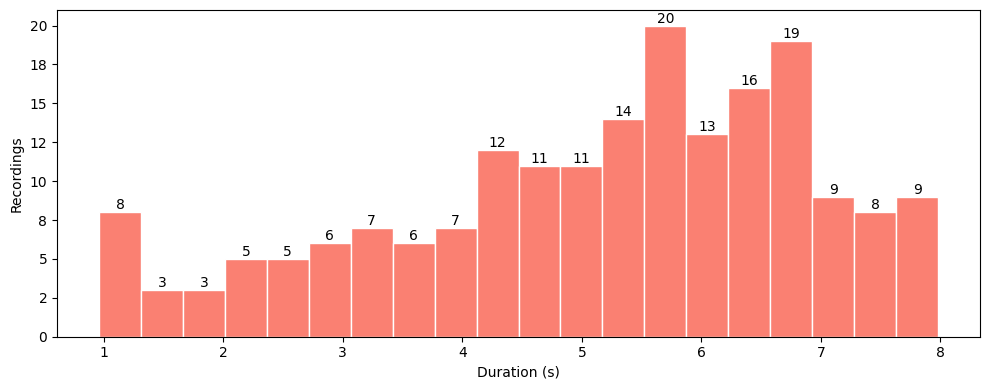

In [85]:
durations = selected_details["Duration (s)"]
print(f"Minimum: {durations.min():.2f} s | Maximum: {durations.max():.2f} s | Average: {durations.mean():.2f} s")

fig, ax = plt.subplots(figsize=(10, 4))
counts, bins, patches = ax.hist(durations, bins=20, color=static_cmap[0], edgecolor="white")
ax.set_xlabel("Duration (s)")
ax.set_ylabel("Recordings")
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.0f'))
ax.bar_label(patches)

plt.tight_layout()
plt.show()

### Training and Validation Split

The selected recordings are split into training (90%) and validation (10%) sets, using the fixed seed from section 1 for reproducibility.

In [86]:
train_index, val_index = train_test_split(selected_recordings.index, test_size=0.1, random_state=gen_seed)
selected_recordings["split"] = "train"
selected_recordings.loc[val_index, "split"] = "val"
selected_recordings["duration"] = selected_details["Duration (s)"]

### Dataset Summary

Number of recordings in the training and validation sets.

In [87]:
split_names = {"train": "Training", "val": "Validation"}

summary = selected_recordings.groupby("split")["duration"].agg(**{
    "Recordings": "count",
    "Total duration (min)": lambda d: d.sum() / 60,
    "Average duration (s)": "mean",
}).rename(index=split_names)
summary.round(3)

,Recordings,Total duration (min),Average duration (s)
split,,,
Training,172,14.762,5.150
Validation,20,1.624,4.872


The number of recordings in each set, and the distribution of recording durations in each set (as a share of its recordings, since the sets differ in size), show whether the validation set is representative of the training set.

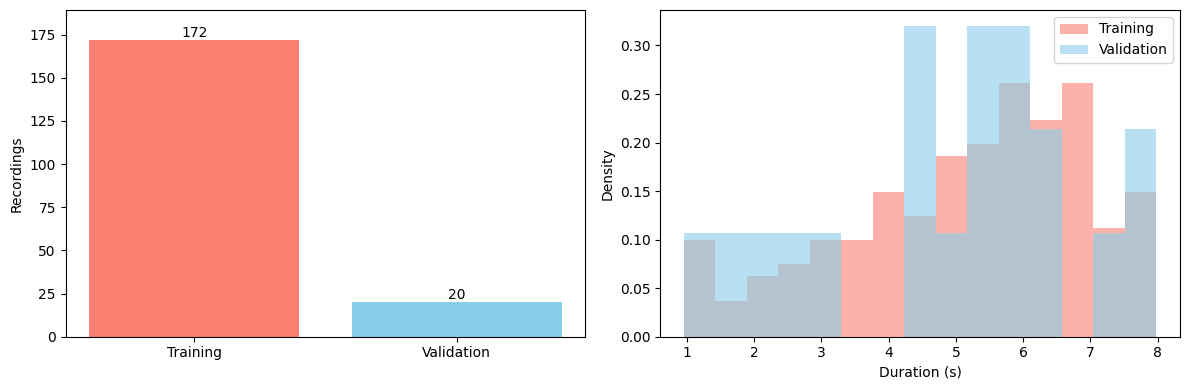

In [88]:
fig, (ax_count, ax_duration) = plt.subplots(1, 2, figsize=(12, 4))
colours = dict(zip(split_names.values(), static_cmap))

bars = ax_count.bar(summary.index, summary["Recordings"], color=[colours[name] for name in summary.index])
ax_count.bar_label(bars)
ax_count.margins(y=0.1)
ax_count.set_ylabel("Recordings")

bins = np.histogram_bin_edges(selected_recordings["duration"], bins=15)
for split, name in split_names.items():
    ax_duration.hist(selected_recordings.loc[selected_recordings["split"] == split, "duration"], bins=bins, density=True,
                     alpha=0.6, color=colours[name], label=name)
ax_duration.set_xlabel("Duration (s)")
ax_duration.set_ylabel("Density")
ax_duration.legend()

plt.tight_layout()
plt.show()

### Writing the Dataset in TTS Format

#### Creating the Metadata Files

In [89]:
training_metadata = selected_recordings[selected_recordings["split"] == "train"][["dataset_id", "text"]]
training_metadata["combined"] = training_metadata[["dataset_id", "text"]].agg("|".join, axis=1)
training_metadata = training_metadata["combined"]
training_metadata.to_csv(metadata_train_path, index=False, header=False)

training_metadata

0      0001|ar žinojai kad vikingai niekada nedėvėjo ...
1      0002|tu įsivaizduoji su tokiais šalmais buvo n...
2      0003|eik tu sau ūžesys kurį girdime sklindant ...
3      0004|yra visai ne jūros ošimas o mus supančios...
5      0006|monako kariuomenės pajėgos sudaro aštuoni...
                             ...                        
185    0186|eik tu sau alkoholis plečia periferines k...
187    0188|nepaisant užgaulių prasimanymų napoleonas...
188    0189|nepatikėsi vorai kryžiuočiai kiekvieną ry...
189    0190|neįtikėtiną prancūzijoje balandžiai vadin...
190    0191|ar gali patikėt didysis benas nėra nei bo...
Name: combined, Length: 172, dtype: object

In [90]:
validation_metadata = selected_recordings[selected_recordings["split"] == "val"][["dataset_id", "text"]]
validation_metadata["combined"] = validation_metadata[["dataset_id", "text"]].agg("|".join, axis=1)
validation_metadata = validation_metadata["combined"]
validation_metadata.to_csv(metadata_val_path, index=False, header=False)

validation_metadata

4      0005|ar girdėjai kad kazino lošimo namuose neb...
12     0013|ar gali patikėti upiniai delfinai gyvena ...
19     0020|atrodo nesąmonė bet ozonas apsaugantis že...
21     0022|ar žinojai kad senais laikais gruodžio ke...
37     0038|atoslūgius bet ir žemės plutos svyravimus...
55         0056|stručiai niekada neslepia galvos smėlyje
61     0062|kad jų lietaus dievas dgai visus galvijus...
62     0063|todėl visi kiti laikantieji galvijus juos...
87                                  0088|atrodo nesąmonė
97     0098|neįtikėtinas sutapimas kad kai kurie gais...
115    0116|tiesą mes kalbaneme ne apie pienišką o ap...
128              0129|gėlo vandens telkinių ir upių tūrį
139    0140|kad sausojo įstatymo metu pusė visų kalin...
148    0149|ar gali patikėti plaukų kirpimas neturi į...
158                                0159|ar gali patikėti
162    0163|ar žinojai kad kai kurie žmonės turi gene...
177               0178|tu įsivaizduoji pūčkorių atodanga
183    0184|ar žinojai kad arab

### Segmenting Recordings to Different Directories

In [91]:
training_wavs_path.mkdir(parents=True, exist_ok=True)

for old_wav in training_wavs_path.glob("*.wav"):
    old_wav.unlink()

training_recordings = selected_recordings[selected_recordings["split"] == "train"]
for source, dataset_id in zip(training_recordings["wav_path"], training_recordings["dataset_id"]):
    shutil.copy(source, training_wavs_path / f"{dataset_id}.wav")

print(f"Copied {len(list(training_wavs_path.glob('*.wav')))} training recordings to {training_wavs_path}")

Copied 172 training recordings to C:\Users\Lenovo\Desktop\vu_masters\1_semester\natural_language_and_speech_processing\6_assignments\task_3\emo_corpus\used_dataset\training_wavs


In [92]:
val_wavs_path.mkdir(parents=True, exist_ok=True)

for old_wav in val_wavs_path.glob("*.wav"):
    old_wav.unlink()

validation_recordings = selected_recordings[selected_recordings["split"] == "val"]
for source, dataset_id in zip(validation_recordings["wav_path"], validation_recordings["dataset_id"]):
    shutil.copy(source, val_wavs_path / f"{dataset_id}.wav")

print(f"Copied {len(list(val_wavs_path.glob('*.wav')))} validation recordings to {val_wavs_path}")

Copied 20 validation recordings to C:\Users\Lenovo\Desktop\vu_masters\1_semester\natural_language_and_speech_processing\6_assignments\task_3\emo_corpus\used_dataset\val_wavs


## 5. Fine-Tuning YourTTS

### Training YourTTS with Lithuanian Speech

In [93]:
split_wavs_paths = {metadata_train_path.name: training_wavs_path, metadata_val_path.name: val_wavs_path}


def emo_formatter(root_path, manifest_file, **kwargs):
    items = []
    with open(Path(root_path) / manifest_file, "r", encoding="utf-8") as metadata_file:
        for line in metadata_file:
            dataset_id, text = line.rstrip("\n").split("|")
            items.append({"text": text, "audio_file": str(split_wavs_paths[manifest_file] / f"{dataset_id}.wav"),
                          "speaker_name": f"emo_{speaker_id}", "root_path": str(root_path)})
    return items


emo_dataset_config = BaseDatasetConfig(dataset_name="emo", path=str(metadata_train_path.parent), language="lt",
                                       meta_file_train=metadata_train_path.name, meta_file_val=metadata_val_path.name)
training_samples, validation_samples = load_tts_samples(emo_dataset_config, eval_split=True, formatter=emo_formatter)

print(f"Training samples: {len(training_samples)} | Validation samples: {len(validation_samples)}")
training_samples[0]

 | > Found 172 files in C:\Users\Lenovo\Desktop\vu_masters\1_semester\natural_language_and_speech_processing\6_assignments\task_3\emo_corpus\used_dataset
Training samples: 172 | Validation samples: 20


{'text': 'ar žinojai kad vikingai niekada nedėvėjo šalmų su ragais',
 'audio_file': 'C:\\Users\\Lenovo\\Desktop\\vu_masters\\1_semester\\natural_language_and_speech_processing\\6_assignments\\task_3\\emo_corpus\\used_dataset\\training_wavs\\0001.wav',
 'speaker_name': 'emo_29',
 'root_path': 'C:\\Users\\Lenovo\\Desktop\\vu_masters\\1_semester\\natural_language_and_speech_processing\\6_assignments\\task_3\\emo_corpus\\used_dataset',
 'language': 'lt',
 'audio_unique_name': 'emo#training_wavs\\0001'}

### Preparing the Fine-Tuning Data

#### Audio Format, Speaker Embeddings and Vocabulary

- YourTTS trains on 16 kHz mono audio, so converted copies of the training and validation recordings are written to `finetune/wavs_16k/`.
- The model is conditioned on a speaker embedding (d-vector) of every recording, computed with the model's own speaker encoder.
- Lithuanian letters missing from the model's vocabulary (e.g. š, ė) are added, together with a new language label `lt`. These start untrained; all other weights come from the pretrained model.

In [94]:
model_dir = Path(tts.synthesizer.tts_checkpoint).parent
wavs_16k_path = finetune_path / "wavs_16k"
d_vector_path = finetune_path / "d_vectors.pth"
prepared_path = finetune_path / "prepared_recordings.json"
finetune_path.mkdir(exist_ok=True)

prepared_recordings = selected_recordings[["dataset_id", "file", "split"]].values.tolist()
saved_recordings = json.loads(prepared_path.read_text()) if prepared_path.exists() else None

if saved_recordings == prepared_recordings and d_vector_path.exists():
    train_samples = speechsynth.samples_to_16k(training_samples, wavs_16k_path)
    val_samples = speechsynth.samples_to_16k(validation_samples, wavs_16k_path)
else:
    for old_wav in wavs_16k_path.glob("*.wav"):
        old_wav.unlink()

    train_samples = speechsynth.samples_to_16k(training_samples, wavs_16k_path)
    val_samples = speechsynth.samples_to_16k(validation_samples, wavs_16k_path)
    speechsynth.compute_d_vectors(train_samples + val_samples, tts.synthesizer.tts_model.speaker_manager, d_vector_path)
    prepared_path.write_text(json.dumps(prepared_recordings))

new_chars = speechsynth.missing_characters(model_dir, [sample["text"] for sample in train_samples + val_samples] + [sentence_lt])

print(f"Training: {len(train_samples)} | Validation: {len(val_samples)} recordings")
print(f"Letters added to the vocabulary: {' '.join(new_chars)}")

Training: 172 | Validation: 20 recordings
Letters added to the vocabulary: č ė į š ų ž


### Fine-Tuning with the Base Training Settings

The pretrained model is fine-tuned with the TTS library's `Trainer`, following the steps of the Coqui TTS training recipe: a training configuration, a model built from it, and a trainer that fits the model on the training samples and evaluates it on the validation samples after every epoch. Unlike the recipe, the model is not trained from scratch, but starts from the pretrained YourTTS weights.

The training settings are the ones YourTTS was originally trained with. Only two values are lowered to fit the laptop:
- **Batch size:** 16 instead of 52, as 52 recordings per batch do not fit into the 8 GB of GPU memory;
- **Number of epochs:** 100 instead of 1,000.

The checkpoint with the lowest validation mel-spectrogram loss is kept as `best_model.pth` in the run folder `finetune/base-<date and time>/`.

#### Training Configuration

In [95]:
base_epochs = 100
base_params = {"batch_size": 16}

base_config = speechsynth.make_config(model_dir, d_vector_path, new_chars, base_params, epochs=base_epochs,
                                      output_path=finetune_path, run_name="base", seed=gen_seed, save=True)

pd.Series({
    "Training samples": len(train_samples),
    "Validation samples": len(val_samples),
    "Epochs": base_config.epochs,
    "Batch size": base_config.batch_size,
    "Optimiser": base_config.optimizer,
    "Loss Function": base_config.target_loss,
    "Learning rate (generator)": base_config.lr_gen
})

Training samples                  172
Validation samples                 20
Epochs                            100
Batch size                         16
Optimiser                       AdamW
Loss Function                loss_mel
Learning rate (generator)      0.0002
dtype: object

#### Model Training

In [96]:
base_history_path = finetune_path / "base_history.csv"
base_run_info_path = finetune_path / "base_run.json"
base_settings = {"epochs": base_config.epochs, "batch_size": base_config.batch_size}
saved_run = json.loads(base_run_info_path.read_text()) if base_run_info_path.exists() else {}

if saved_run.get("settings") == base_settings and (finetune_path / saved_run["run_folder"] / "best_model.pth").exists():
    base_run_path = finetune_path / saved_run["run_folder"]
    base_training_time = saved_run["training_time"]
    base_history = pd.read_csv(base_history_path)
else:
    base_history, base_training_time, base_run_path = speechsynth.fine_tune(base_config, model_dir, new_chars,
                                                                           train_samples, val_samples)
    base_history.to_csv(base_history_path, index=False)
    base_run_info_path.write_text(json.dumps({"run_folder": Path(base_run_path).name, "settings": base_settings,
                                              "training_time": base_training_time}, indent=1))

print(f"Total training time: {base_training_time / 60:.1f} min | Run folder: {Path(base_run_path).name}")

Total training time: 168.8 min | Run folder: base-October-08-2026_05+38PM-0000000


#### Tuning Results

Training and validation losses after the first, the best and the last epoch. The best epoch has the lowest validation mel-spectrogram loss, and its weights are kept as the fine-tuned model.

In [97]:
best_epoch = base_history["val_loss_mel"].idxmin()
key_epochs = {"First epoch": 0, "Best epoch": best_epoch, "Last epoch": len(base_history) - 1}
losses = {"train_loss_mel": "Training mel loss", "val_loss_mel": "Validation mel loss",
          "train_loss_1": "Training total loss", "val_loss_1": "Validation total loss"}

tuning_results = base_history.loc[list(key_epochs.values()), list(losses)].rename(columns=losses)
tuning_results.index = [f"{name} ({epoch + 1})" for name, epoch in key_epochs.items()]
tuning_results.round(3)

,Training mel loss,Validation mel loss,Training total loss,Validation total loss
First epoch (1),22.895,22.794,32.337,31.682
Best epoch (67),19.811,18.288,27.012,25.438
Last epoch (100),18.994,19.841,26.184,27.721


#### Training Summary

In [98]:
pd.Series({
    "Training samples": len(train_samples),
    "Validation samples": len(val_samples),
    "Epochs": base_config.epochs,
    "Batch size": base_config.batch_size,
    "Learning rate (generator)": base_config.lr_gen,
    "Best epoch": best_epoch + 1,
    "Total training time (min)": round(base_training_time / 60, 1),
    "Run folder": Path(base_run_path).name,
})

Training samples                                              172
Validation samples                                             20
Epochs                                                        100
Batch size                                                     16
Learning rate (generator)                                  0.0002
Best epoch                                                     67
Total training time (min)                                   168.8
Run folder                   base-October-08-2026_05+38PM-0000000
dtype: object

#### Loss Curves

Training and validation losses after every epoch. The mel-spectrogram loss measures how close the generated speech is to the real recording. The total generator loss also includes the adversarial, KL divergence, duration and speaker consistency terms. The dashed line marks the best epoch.

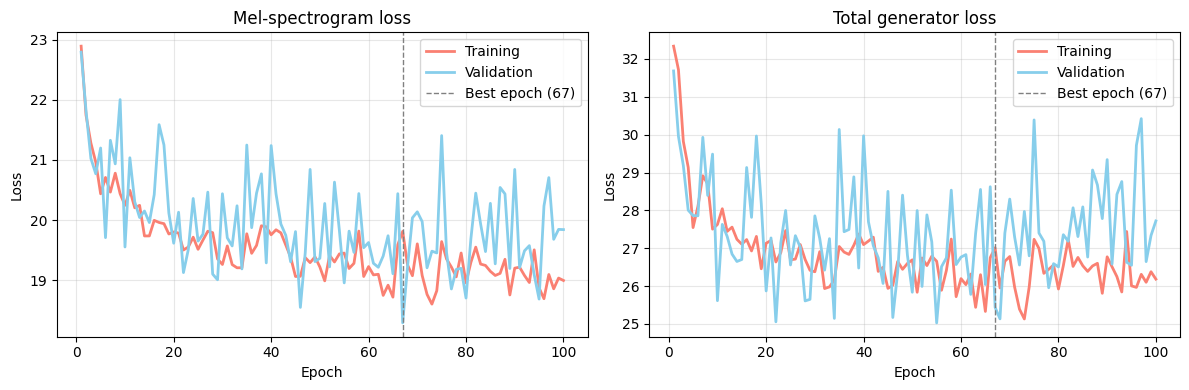

In [99]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = np.arange(1, len(base_history) + 1)
for ax, (loss, title) in zip(axes, {"loss_mel": "Mel-spectrogram loss", "loss_1": "Total generator loss"}.items()):
    for split, name, colour in zip(["train", "val"], ["Training", "Validation"], static_cmap):
        ax.plot(epochs, base_history[f"{split}_{loss}"], color=colour, linewidth=2, label=name)
    ax.axvline(best_epoch + 1, color="grey", linestyle="--", linewidth=1, label=f"Best epoch ({best_epoch + 1})")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

#### Tuned Model Comparison

##### Synthesising the Sentence

In [100]:
from TTS.utils.synthesizer import Synthesizer

finetuned_model_path = Path(base_run_path)
synthesizer_finetuned = Synthesizer(tts_checkpoint=str(finetuned_model_path / "best_model.pth"),
                                    tts_config_path=str(finetuned_model_path / "config.json"),
                                    use_cuda=device == "cuda")

output_lt_finetuned_path = outputs_path / "output_lt_finetuned.wav"
torch.manual_seed(gen_seed)
wav_lt_finetuned = synthesizer_finetuned.tts(text=sentence_lt, speaker_wav=str(reference_lt_path), language_name="lt")
synthesizer_finetuned.save_wav(wav_lt_finetuned, str(output_lt_finetuned_path))

 > Using model: vits
 > Setting up Audio Processor...
 | > sample_rate:16000
 | > resample:False
 | > num_mels:80
 | > log_func:np.log10
 | > min_level_db:0
 | > frame_shift_ms:None
 | > frame_length_ms:None
 | > ref_level_db:None
 | > fft_size:1024
 | > power:None
 | > preemphasis:0.0
 | > griffin_lim_iters:None
 | > signal_norm:None
 | > symmetric_norm:None
 | > mel_fmin:0
 | > mel_fmax:None
 | > pitch_fmin:None
 | > pitch_fmax:None
 | > spec_gain:20.0
 | > stft_pad_mode:reflect
 | > max_norm:1.0
 | > clip_norm:True
 | > do_trim_silence:False
 | > trim_db:60
 | > do_sound_norm:False
 | > do_amp_to_db_linear:True
 | > do_amp_to_db_mel:True
 | > do_rms_norm:False
 | > db_level:None
 | > stats_path:None
 | > base:10
 | > hop_length:256
 | > win_length:1024
 > Model fully restored. 
 > Setting up Audio Processor...
 | > sample_rate:16000
 | > resample:False
 | > num_mels:64
 | > log_func:np.log10
 | > min_level_db:-100
 | > frame_shift_ms:None
 | > frame_length_ms:None
 | > ref_level_db:

C:\Users\Lenovo\AppData\Roaming\Python\Python310\site-packages\TTS\tts\utils\managers.py:20: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(f, map_location=

 > Model fully restored. 
 > Setting up Audio Processor...
 | > sample_rate:16000
 | > resample:False
 | > num_mels:64
 | > log_func:np.log10
 | > min_level_db:-100
 | > frame_shift_ms:None
 | > frame_length_ms:None
 | > ref_level_db:20
 | > fft_size:512
 | > power:1.5
 | > preemphasis:0.97
 | > griffin_lim_iters:60
 | > signal_norm:False
 | > symmetric_norm:False
 | > mel_fmin:0
 | > mel_fmax:8000.0
 | > pitch_fmin:1.0
 | > pitch_fmax:640.0
 | > spec_gain:20.0
 | > stft_pad_mode:reflect
 | > max_norm:4.0
 | > clip_norm:False
 | > do_trim_silence:False
 | > trim_db:60
 | > do_sound_norm:False
 | > do_amp_to_db_linear:True
 | > do_amp_to_db_mel:True
 | > do_rms_norm:True
 | > db_level:-27.0
 | > stats_path:None
 | > base:10
 | > hop_length:160
 | > win_length:400
 > Text splitted to sentences.
['Tai yra šnekos sintezės sistemos testas.']
 > Processing time: 0.35088300704956055
 > Real-time factor: 0.07943921373093968


##### Quality of the Synthesised Speech

In [101]:
synth_lt_finetuned, synth_lt_finetuned_sr = speechsynth.load_recording(output_lt_finetuned_path, sr=model_sr)

signals_lt_finetuned = {
    "Natural": (reference_lt, reference_lt_sr),
    "Fine-tuned": (synth_lt_finetuned, synth_lt_finetuned_sr),
}
signals_lt_all = {
    "Natural": (reference_lt, reference_lt_sr),
    "Synthesised": (synth_lt, synth_lt_sr),
    "Fine-tuned": (synth_lt_finetuned, synth_lt_finetuned_sr),
}
speechsynth.play_side_by_side(signals_lt_all)

##### Waveforms

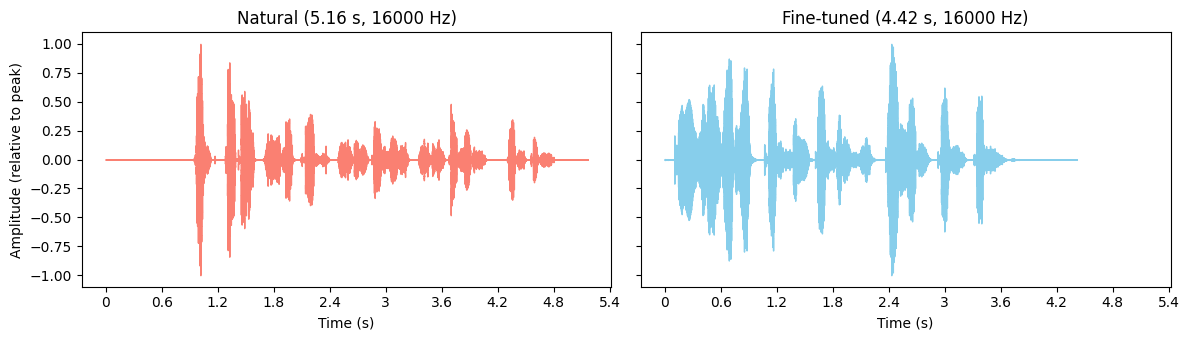

In [102]:
speechsynth.plot_waveforms(signals_lt_finetuned, colours=static_cmap)

##### Magnitude Spectrum

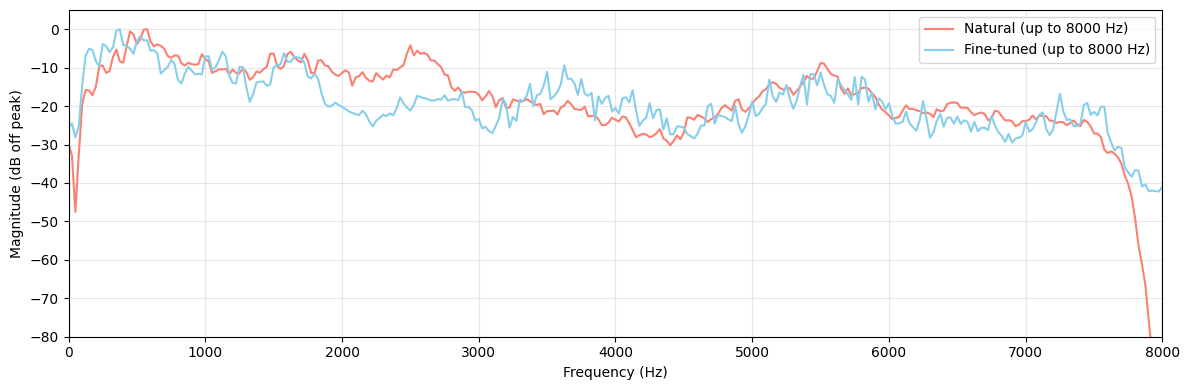

In [103]:
speechsynth.plot_magnitude_spectra(signals_lt_finetuned, colours=static_cmap)

##### Spectrograms

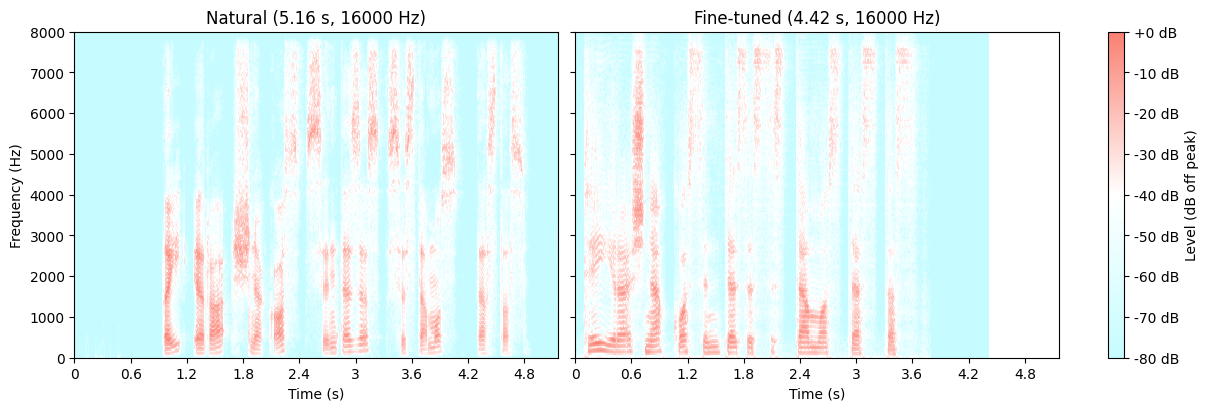

In [104]:
speechsynth.plot_spectrograms(signals_lt_finetuned, cmap=cmap)

##### F0 Contours on Normalised Time

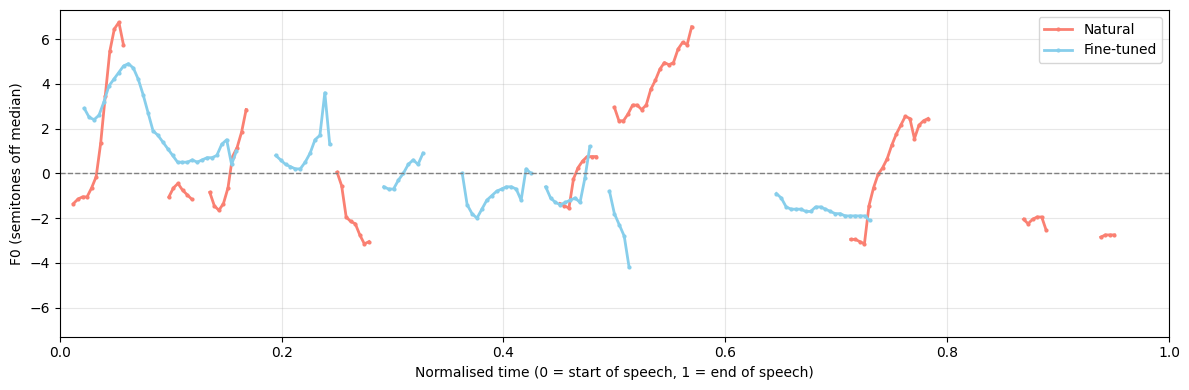

In [105]:
f0_lt_finetuned = speechsynth.f0_contours(signals_lt_finetuned)
speechsynth.plot_f0_normalised(signals_lt_finetuned, f0_lt_finetuned, colours=static_cmap)

##### Observed Differences

In [106]:
f0_lt_all = {"Natural": f0_lt["Natural"], "Synthesised": f0_lt["Synthesised"], "Fine-tuned": f0_lt_finetuned["Fine-tuned"]}

comparison_lt_finetuned = speechsynth.signal_comparison(signals_lt_all, f0_lt_all)
comparison_lt_finetuned.round(3)

,Natural,Synthesised,Fine-tuned
Duration (s),5.163,3.889,4.417
Speech duration (s),3.904,3.200,3.616
Sampling frequency (Hz),16000.000,16000.000,16000.000
RMS level (dBFS),-42.598,-20.037,-18.801
Spectral centroid (Hz),3010.783,3182.539,2963.457
F0 mean (Hz),126.893,124.521,140.987
F0 std (Hz),20.932,9.451,15.891
F0 min (Hz),100.693,104.848,109.174
F0 max (Hz),178.381,149.136,184.672
F0 range (semitones),9.900,6.100,9.100
